# ¡Llena ese carrito!

# Introducción

Instacart es una plataforma de entregas de comestibles donde la clientela puede registrar un pedido y hacer que se lo entreguen, similar a Uber Eats y Door Dash.
El conjunto de datos que te hemos proporcionado tiene modificaciones del original. Redujimos el tamaño del conjunto para que tus cálculos se hicieran más rápido e introdujimos valores ausentes y duplicados. Tuvimos cuidado de conservar las distribuciones de los datos originales cuando hicimos los cambios.

Debes completar tres pasos. Para cada uno de ellos, escribe una breve introducción que refleje con claridad cómo pretendes resolver cada paso, y escribe párrafos explicatorios que justifiquen tus decisiones al tiempo que avanzas en tu solución.  También escribe una conclusión que resuma tus hallazgos y elecciones.


## Diccionario de datos

Hay cinco tablas en el conjunto de datos, y tendrás que usarlas todas para hacer el preprocesamiento de datos y el análisis exploratorio de datos. A continuación se muestra un diccionario de datos que enumera las columnas de cada tabla y describe los datos que contienen.

- `instacart_orders.csv`: cada fila corresponde a un pedido en la aplicación Instacart.
    - `'order_id'`: número de ID que identifica de manera única cada pedido.
    - `'user_id'`: número de ID que identifica de manera única la cuenta de cada cliente.
    - `'order_number'`: el número de veces que este cliente ha hecho un pedido.
    - `'order_dow'`: día de la semana en que se hizo el pedido (0 si es domingo).
    - `'order_hour_of_day'`: hora del día en que se hizo el pedido.
    - `'days_since_prior_order'`: número de días transcurridos desde que este cliente hizo su pedido anterior.
- `products.csv`: cada fila corresponde a un producto único que pueden comprar los clientes.
    - `'product_id'`: número ID que identifica de manera única cada producto.
    - `'product_name'`: nombre del producto.
    - `'aisle_id'`: número ID que identifica de manera única cada categoría de pasillo de víveres.
    - `'department_id'`: número ID que identifica de manera única cada departamento de víveres.
- `order_products.csv`: cada fila corresponde a un artículo pedido en un pedido.
    - `'order_id'`: número de ID que identifica de manera única cada pedido.
    - `'product_id'`: número ID que identifica de manera única cada producto.
    - `'add_to_cart_order'`: el orden secuencial en el que se añadió cada artículo en el carrito.
    - `'reordered'`: 0 si el cliente nunca ha pedido este producto antes, 1 si lo ha pedido.
- `aisles.csv`
    - `'aisle_id'`: número ID que identifica de manera única cada categoría de pasillo de víveres.
    - `'aisle'`: nombre del pasillo.
- `departments.csv`
    - `'department_id'`: número ID que identifica de manera única cada departamento de víveres.
    - `'department'`: nombre del departamento.

# Paso 1. Descripción de los datos

Lee los archivos de datos (`/datasets/instacart_orders.csv`, `/datasets/products.csv`, `/datasets/aisles.csv`, `/datasets/departments.csv` y `/datasets/order_products.csv`) con `pd.read_csv()` usando los parámetros adecuados para leer los datos correctamente. Verifica la información para cada DataFrame creado.


## Plan de solución

Escribe aquí tu plan de solución para el Paso 1. Descripción de los datos.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np# importar librerías

In [ ]:
from pathlib import Path
base_candidates = [Path('data_wrangling') / 'dfs', Path('dfs')]
for base in base_candidates:
    if (base / 'order_products.csv').exists():
        orders= pd.read_csv(base / 'order_products.csv', sep=';')
        products= pd.read_csv(base / 'products.csv', sep=';')
        aisles= pd.read_csv(base / 'aisles.csv', sep=';')
        departments= pd.read_csv(base / 'departments.csv', sep=';')
        order_products= pd.read_csv(base / 'order_products.csv', sep=';')  # leer conjuntos de datos en los DataFrames
        break
else:
    raise FileNotFoundError('No se encontraron los CSV en data_wrangling/dfs o dfs/')

In [3]:
print(orders.info(), orders.head())
print('--SEPARADOR----')# mostrar información del DataFrame

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 478967 entries, 0 to 478966
Data columns (total 6 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   order_id                478967 non-null  int64  
 1   user_id                 478967 non-null  int64  
 2   order_number            478967 non-null  int64  
 3   order_dow               478967 non-null  int64  
 4   order_hour_of_day       478967 non-null  int64  
 5   days_since_prior_order  450148 non-null  float64
dtypes: float64(1), int64(5)
memory usage: 21.9 MB
None    order_id  user_id  order_number  order_dow  order_hour_of_day  \
0   1515936   183418            11          6                 13   
1   1690866   163593             5          5                 12   
2   1454967    39980             4          5                 19   
3   1768857    82516            56          0                 20   
4   3007858   196724             2          4                 

In [4]:
print(products.info(), products.head())
print('--SEPARADOR----')# mostrar información del DataFrame

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49694 entries, 0 to 49693
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   product_id     49694 non-null  int64 
 1   product_name   48436 non-null  object
 2   aisle_id       49694 non-null  int64 
 3   department_id  49694 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 1.5+ MB
None    product_id                                       product_name  aisle_id  \
0           1                         Chocolate Sandwich Cookies        61   
1           2                                   All-Seasons Salt       104   
2           3               Robust Golden Unsweetened Oolong Tea        94   
3           4  Smart Ones Classic Favorites Mini Rigatoni Wit...        38   
4           5                          Green Chile Anytime Sauce         5   

   department_id  
0             19  
1             13  
2              7  
3              1  
4             1

In [5]:
print(aisles.info(), aisles.head())
print('--SEPARADOR----')# mostrar información del DataFrame

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 134 entries, 0 to 133
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   aisle_id  134 non-null    int64 
 1   aisle     134 non-null    object
dtypes: int64(1), object(1)
memory usage: 2.2+ KB
None    aisle_id                       aisle
0         1       prepared soups salads
1         2           specialty cheeses
2         3         energy granola bars
3         4               instant foods
4         5  marinades meat preparation
--SEPARADOR----


In [6]:
print(departments.info(), departments.head())
print('--SEPARADOR----')# mostrar información del DataFrame

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   department_id  21 non-null     int64 
 1   department     21 non-null     object
dtypes: int64(1), object(1)
memory usage: 464.0+ bytes
None    department_id department
0              1     frozen
1              2      other
2              3     bakery
3              4    produce
4              5    alcohol
--SEPARADOR----


In [7]:
print(order_products.info( show_counts= True), order_products.head())# mostrar información del DataFrame

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4545007 entries, 0 to 4545006
Data columns (total 4 columns):
 #   Column             Non-Null Count    Dtype  
---  ------             --------------    -----  
 0   order_id           4545007 non-null  int64  
 1   product_id         4545007 non-null  int64  
 2   add_to_cart_order  4544171 non-null  float64
 3   reordered          4545007 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 138.7 MB
None    order_id  product_id  add_to_cart_order  reordered
0   2141543       11440               17.0          0
1    567889        1560                1.0          1
2   2261212       26683                1.0          1
3    491251        8670               35.0          1
4   2571142        1940                5.0          1


<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a><br />
Correcto!<br/>
Buena manera de leer los datos y buenas observaciones iniciales.<br/>
 
</div>


## Conclusiones

Escribe aquí tus conclusiones intermedias sobre el Paso 1. Descripción de los datos.
Hasta aqui podemos obersvar algunos problemas con los dataframes antes de poder trabajar con ellos, los cuales se enuncian a continuacion:
 en df0 yo considero que los dias en los que no se ha pedido se contabiliza el dia completo no por facciones por lo tanto este dato deberia ser int, ademas de que tenemos datos faltantes.
 en df1 en product_name tenemos datos faltanes,
 y en df4 tenemos igual datos daltanes.

# Paso 2. Preprocesamiento de los datos

Preprocesa los datos de la siguiente manera:

- Verifica y corrige los tipos de datos (por ejemplo, asegúrate de que las columnas de ID sean números enteros).
- Identifica y completa los valores ausentes.
- Identifica y elimina los valores duplicados.

Asegúrate de explicar qué tipos de valores ausentes y duplicados encontraste, cómo los completaste o eliminaste y por qué usaste esos métodos. ¿Por qué crees que estos valores ausentes y duplicados pueden haber estado presentes en el conjunto de datos?

## Plan de solución

Escribe aquí tu plan para el Paso 2. Preprocesamiento de los datos.
revisar los datos duplicados y eliminarlos si es lo mas conveniente, tambienn verificar cual seria la manera mas adecuada de llenar los valores ausentes, y cambiar los datos a los tipos de datos correctos segun corresponda 

## Encuentra y elimina los valores duplicados (y describe cómo tomaste tus decisiones).

### `orders` data frame

In [8]:
print(orders.duplicated().sum())
orders[orders.duplicated(keep=False)].sample(5)
# Revisa si hay pedidos duplicados


15


,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
273805,1112182,202304,84,3,2,6.0
259636,2282673,86751,49,3,2,2.0
99462,794638,50898,24,3,2,2.0
257934,1919531,191501,32,3,2,7.0
324868,2232988,82565,1,3,2,NaN


¿Tienes líneas duplicadas? si ¿qué tienen en común? que todas fueron el miercoles a las 2.

In [9]:
# Basándote en tus hallazgos,
# Verifica todos los pedidos que se hicieron el miércoles a las 2:00 a.m.
print(orders[(orders['order_dow']==3)&(orders['order_hour_of_day']==2)])

        order_id  user_id  order_number  order_dow  order_hour_of_day  \
4838     2766110   162084            41          3                  2   
5156     2190225   138285            18          3                  2   
15506     553049    58599            13          3                  2   
18420     382357   120200            19          3                  2   
24691     690242    77357             2          3                  2   
...          ...      ...           ...        ...                ...   
457013   3384021    14881             6          3                  2   
458816    910166   164782            18          3                  2   
459635   1680532   106435             6          3                  2   
468324    222962    54979            59          3                  2   
477526   2592344    46860            38          3                  2   

        days_since_prior_order  
4838                      16.0  
5156                      11.0  
15506                   

¿Qué sugiere este resultado?
probablemente algun error a esa hora y ese dia. 

In [10]:
orders.drop_duplicates(inplace=True)
orders.reset_index(drop=True, inplace=True)# Elimina los pedidos duplicados


In [11]:
print(orders.duplicated().sum())# Vuelve a verificar si hay filas duplicadas


0


In [12]:
print(orders['order_id'].duplicated().sum())# Vuelve a verificar únicamente si hay IDs duplicados de pedidos


0


Describe brevemente tus hallazgos y lo que hiciste con ellos
Ya no hay duplicados, y pudimos ver que solo los miercoles a las 2 se creaban datos duplicados.

<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a><br />
Bien hecho!<br/>
Los duplicados fueron eliminados correctamente
</div>


### `products` data frame

In [13]:
print(products.duplicated().sum())# Verifica si hay filas totalmente duplicadas


0


In [14]:
print(products['product_id'].duplicated().sum())# Revisa únicamente si hay ID de productos duplicados




0


In [15]:
nombres_mayusculas = []

for nombre in products['product_name']:
    if isinstance(nombre, str):
        nombres_mayusculas.append(nombre.upper())
    else:
        nombres_mayusculas.append(nombre)  # deja NaN tal cual

products['product_name'] = nombres_mayusculas




# Revisa únicamente si hay nombres duplicados de productos (convierte los nombres a letras mayúsculas para compararlos mejor)


In [16]:
print(products['product_name'].duplicated().sum())# Revisa si hay nombres duplicados de productos no faltantes


1361


Describe brevemente tus hallazgos y lo que hiciste con ellos.

tenemos datos duplicados sin embargo para este data fram considero que debemos dejarlos, con excepcion de los de sin nombre

<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a><br />
Bien hecho!<br/>
Los datos han sido revisados apropiadamente
</div>


### `departments` data frame


In [17]:
print(departments.duplicated().sum())# Revisa si hay filas totalmente duplicadas

0


In [18]:
print(departments['department_id'].duplicated().sum())# Revisa únicamente si hay IDs duplicadas de departamentos

0


Describe brevemente tus hallazgos y lo que hiciste con ellos.

Este data frame parece no contener datos duplicados

### `aisles` data frame

In [19]:
print(aisles.duplicated().sum())# Revisa si hay filas totalmente duplicadas

0


In [20]:
print(aisles['aisle_id'].duplicated().sum())# Revisa únicamente si hay IDs duplicadas de pasillos

0


Describe brevemente tus hallazgos y lo que hiciste con ellos.

Este data drmae igual no contiene informacion duplicada.

### `order_products` data frame

In [21]:
print(order_products.duplicated().sum())# Revisa si hay filas totalmente duplicadas


0


In [22]:
aisles_limpio= aisles['aisle'].str.strip().str.upper()
print(sorted(aisles_limpio))# Vuelve a verificar si hay cualquier otro duplicado engañoso


['AIR FRESHENERS CANDLES', 'ASIAN FOODS', 'BABY ACCESSORIES', 'BABY BATH BODY CARE', 'BABY FOOD FORMULA', 'BAKERY DESSERTS', 'BAKING INGREDIENTS', 'BAKING SUPPLIES DECOR', 'BEAUTY', 'BEERS COOLERS', 'BODY LOTIONS SOAP', 'BREAD', 'BREAKFAST BAKERY', 'BREAKFAST BARS PASTRIES', 'BULK DRIED FRUITS VEGETABLES', 'BULK GRAINS RICE DRIED GOODS', 'BUNS ROLLS', 'BUTTER', 'CANDY CHOCOLATE', 'CANNED FRUIT APPLESAUCE', 'CANNED JARRED VEGETABLES', 'CANNED MEALS BEANS', 'CANNED MEAT SEAFOOD', 'CAT FOOD CARE', 'CEREAL', 'CHIPS PRETZELS', 'CLEANING PRODUCTS', 'COCOA DRINK MIXES', 'COFFEE', 'COLD FLU ALLERGY', 'CONDIMENTS', 'COOKIES CAKES', 'CRACKERS', 'CREAM', 'DEODORANTS', 'DIAPERS WIPES', 'DIGESTION', 'DISH DETERGENTS', 'DOG FOOD CARE', 'DOUGHS GELATINS BAKE MIXES', 'DRY PASTA', 'EGGS', 'ENERGY GRANOLA BARS', 'ENERGY SPORTS DRINKS', 'EYE EAR CARE', 'FACIAL CARE', 'FEMININE CARE', 'FIRST AID', 'FOOD STORAGE', 'FRESH DIPS TAPENADES', 'FRESH FRUITS', 'FRESH HERBS', 'FRESH PASTA', 'FRESH VEGETABLES', 'FR

Describe brevemente tus hallazgos y lo que hiciste con ellos.

aqui no logre detectar duplicados engañosos 

<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a><br />
Correcto!<br/>
Estos últimos dataframes no cuentan con filas totalmente duplicadas.

</div>


## Encuentra y elimina los valores ausentes

Al trabajar con valores duplicados, pudimos observar que también nos falta investigar valores ausentes:

* La columna `'product_name'` de la tabla products.
* La columna `'days_since_prior_order'` de la tabla orders.
* La columna `'add_to_cart_order'` de la tabla order_productos.

### `products` data frame

In [23]:
print(products[products['product_name'].isna()])# Encuentra los valores ausentes en la columna 'product_name'

       product_id product_name  aisle_id  department_id
37             38          NaN       100             21
71             72          NaN       100             21
109           110          NaN       100             21
296           297          NaN       100             21
416           417          NaN       100             21
...           ...          ...       ...            ...
49552       49553          NaN       100             21
49574       49575          NaN       100             21
49640       49641          NaN       100             21
49663       49664          NaN       100             21
49668       49669          NaN       100             21

[1258 rows x 4 columns]


Describe brevemente cuáles son tus hallazgos
todos estan relacionados al mismo aisle y department id

In [24]:
#  ¿Todos los nombres de productos ausentes están relacionados con el pasillo con ID 100?
print(departments[departments['department_id']==21])
print(aisles[aisles['aisle_id']==100])

    department_id department
20             21    missing
    aisle_id    aisle
99       100  missing


Describe brevemente cuáles son tus hallazgos.

todos estan relacionados al mismo aisle y department id

In [25]:
# ¿Todos los nombres de productos ausentes están relacionados con el departamento con ID 21?


Describe brevemente cuáles son tus hallazgos.si

In [26]:
# Usa las tablas department y aisle para revisar los datos del pasillo con ID 100 y el departamento con ID 21.


Describe brevemente cuáles son tus hallazgos.

si, todos estan relacionados, pero por lo que se entiende son datos perdidos

In [27]:
products['product_name']= products['product_name'].fillna('Unkown')# Completa los nombres de productos ausentes con 'Unknown'


Describe brevemente tus hallazgos y lo que hiciste con ellos.

Ya una vez que hizimos la exploracion de los pasillos y departaments podemos ver que todas esas columnas son datos perdidos

<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a><br />
Bien hecho!<br/>
La manera de encontrar los valores ausentes y reemplazarlos con un valor generico es correcta
</div>


### `orders` data frame

In [28]:
print(orders[(orders['days_since_prior_order'].isna()) & (orders['order_number'] != 1)])

Empty DataFrame
Columns: [order_id, user_id, order_number, order_dow, order_hour_of_day, days_since_prior_order]
Index: []


In [29]:
# ¿Hay algún valor ausente que no sea el primer pedido del cliente?


Describe brevemente tus hallazgos y lo que hiciste con ellos.
no, todas son de la primera ordern. significa que no puede haber prior order

<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a><br />
Bien hecho!<br/>
Buena manera de revisar los datos y encontrar que no hay ausentes que no sean un primer pedido
</div>


### `order_products` data frame

In [30]:
print(order_products[order_products['add_to_cart_order'].isna()])

print(order_products['add_to_cart_order'].min())
print(order_products['add_to_cart_order'].max())# Encuentra los valores ausentes

         order_id  product_id  add_to_cart_order  reordered
737       2449164        5068                NaN          0
9926      1968313       43867                NaN          0
14394     2926893       11688                NaN          0
16418     1717990        4142                NaN          0
30114     1959075       42828                NaN          1
...           ...         ...                ...        ...
4505662   1800005        7411                NaN          0
4511400   1633337         260                NaN          0
4517562    404157        9517                NaN          0
4534112   1673227       17835                NaN          0
4535739   1832957       17949                NaN          1

[836 rows x 4 columns]
1.0
64.0


In [31]:
# ¿Cuáles son los valores mínimos y máximos en esta columna?

Describe brevemente cuáles son tus hallazgos.
los minimos son 1 y maximo es 64m 

In [32]:
lost_ids= order_products[order_products['add_to_cart_order'].isna()]['order_id']# Guarda todas las IDs de pedidos que tengan un valor ausente en 'add_to_cart_order'
print(lost_ids)

737        2449164
9926       1968313
14394      2926893
16418      1717990
30114      1959075
            ...   
4505662    1800005
4511400    1633337
4517562     404157
4534112    1673227
4535739    1832957
Name: order_id, Length: 836, dtype: int64


In [33]:
pedidos_con_valor_ausente = order_products[order_products['add_to_cart_order'].isna()]
conteo_productos_por_pedido= pedidos_con_valor_ausente.groupby('order_id').size()
print(conteo_productos_por_pedido.min())
print(conteo_productos_por_pedido.max())# ¿Todos los pedidos con valores ausentes tienen más de 64 productos?
# Agrupa todos los pedidos con datos ausentes por su ID de pedido.
# Cuenta el número de 'product_id' en cada pedido y revisa el valor mínimo del conteo.


1
63


Describe brevemente cuáles son tus hallazgos. ninguno pasa de 64 

<div class="alert alert-block alert-warning">
<b>Comentario del revisor</b> <a class="tocSkip"></a><br />
Cuidado!<br/>
    
El valor minimo para ordenes que tienen valores nulos es `65`, te dejo el código en la celda de abajo
</div>


In [34]:
# Código del revisor
order_products[order_products['order_id'].isin(lost_ids)].groupby('order_id')['product_id'].count().min()

65

In [35]:
print(order_products[order_products['add_to_cart_order'].isna()])

order_products['add_to_cart_order']=order_products['add_to_cart_order'].fillna(999).astype(int)

print(order_products['add_to_cart_order'].isna().sum())# Remplaza los valores ausentes en la columna 'add_to_cart? con 999 y convierte la columna al tipo entero.


         order_id  product_id  add_to_cart_order  reordered
737       2449164        5068                NaN          0
9926      1968313       43867                NaN          0
14394     2926893       11688                NaN          0
16418     1717990        4142                NaN          0
30114     1959075       42828                NaN          1
...           ...         ...                ...        ...
4505662   1800005        7411                NaN          0
4511400   1633337         260                NaN          0
4517562    404157        9517                NaN          0
4534112   1673227       17835                NaN          0
4535739   1832957       17949                NaN          1

[836 rows x 4 columns]
0


Describe brevemente tus hallazgos y lo que hiciste con ellos. se remplazaron los valores que eran nan por 999.

<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a><br />
Bien hecho!<br/>
La manera de encontrar los valores ausentes y reemplazarlos con un valor generico es correcta
</div>


## Conclusiones

Escribe aquí tus conclusiones intermedias sobre el Paso 2. Preprocesamiento de los datos
Pudimos observar que algunos data frames no era posible trabajar asi como se recibieron los datos, ademas de tener que tomar algunas decisiones sobre como se iban a tratar los datos faltanes, y duplicados, tambien podemos ver que algunos datos no es que fuerna datos faltantes si no que simplemente no existian aun, como el caso de prior order cuando el cliente estaba haicneod su primrera orden.

# Paso 3. Análisis de los datos

Una vez los datos estén procesados y listos, haz el siguiente análisis:

# [A] Fácil (deben completarse todos para aprobar)

1. Verifica que los valores en las columnas `'order_hour_of_day'` y `'order_dow'` en la tabla orders sean razonables (es decir, `'order_hour_of_day'` oscile entre 0 y 23 y `'order_dow'` oscile entre 0 y 6).
2. Crea un gráfico que muestre el número de personas que hacen pedidos dependiendo de la hora del día.
3. Crea un gráfico que muestre qué día de la semana la gente hace sus compras.
4. Crea un gráfico que muestre el tiempo que la gente espera hasta hacer su siguiente pedido, y comenta sobre los valores mínimos y máximos.

### [A1] Verifica que los valores sean sensibles

In [36]:
print(sorted(orders['order_hour_of_day'].unique()))
print(sorted(orders['order_dow'].unique()))

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23]
[0, 1, 2, 3, 4, 5, 6]


<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a><br />
Bien hecho!<br/>
Se verificó que los datos sean sensibles correctamente
</div>


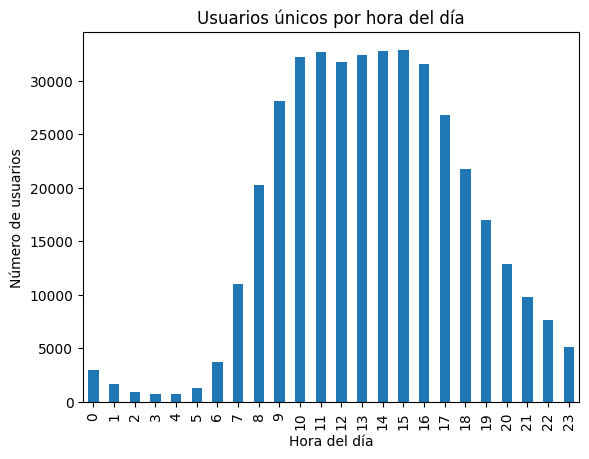

In [37]:
orders.groupby('order_hour_of_day')['user_id'].nunique().plot(
    kind='bar',
    title='Usuarios únicos por hora del día',
    xlabel='Hora del día',
    ylabel='Número de usuarios'
)
plt.show()

<div class="alert alert-block alert-warning">
<b>Comentario del revisor</b> <a class="tocSkip"></a><br />
Cuidado!<br/>

La manera de mostrar los datos es correcta, pero debemos mantener un orden en el proyecto y escribir el código en los lugares que corresponden, esta gráfica debería ir en la sección de abajo
</div>


Escribe aquí tus conclusiones

### [A2] Para cada hora del día, ¿cuántas personas hacen órdenes?

In [39]:
print(orders.groupby('order_hour_of_day')['user_id'].nunique())

order_hour_of_day
0      2991
1      1671
2       958
3       744
4       735
5      1281
6      3757
7     10993
8     20268
9     28112
10    32195
11    32660
12    31754
13    32433
14    32797
15    32894
16    31579
17    26825
18    21795
19    17026
20    12891
21     9806
22     7670
23     5167
Name: user_id, dtype: int64


Escribe aquí tus conclusiones es mucho mas entendible ver un grafico a una lista con datos, aun que sea un poco menos perceptible la cantidad exacta creo que es mas relevante dimensionar el crecimiento

### [A3] ¿Qué día de la semana compran víveres las personas?

<function matplotlib.pyplot.show(close=None, block=None)>

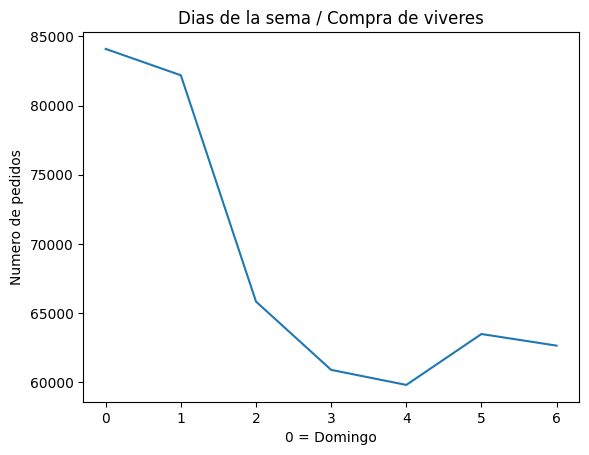

In [40]:
orders.groupby(by='order_dow')['order_id'].count().plot(
    title='Dias de la sema / Compra de viveres',
    xlabel= '0 = Domingo',
    ylabel= 'Numero de pedidos',
    
)
plt.show

Escribe aquí tus conclusiones

Los dias domingo es cuando mas viveres se compran,  de ahi va cayendo considrabemente durante la semana hasta el punto mas bajo que es el jueves y de ahi comienza a subir un poco pero si vieramos el dia domigno al final la subida en los numeros es muy grande entre sabado y domingo

<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a><br />
Correcto!<br/>
Los domingos son los días preferidos de los clientes
</div>


### [A4] ¿Cuánto tiempo esperan las personas hasta hacer otro pedido? Comenta sobre los valores mínimos y máximos.

0.0
30.0


<function matplotlib.pyplot.show(close=None, block=None)>

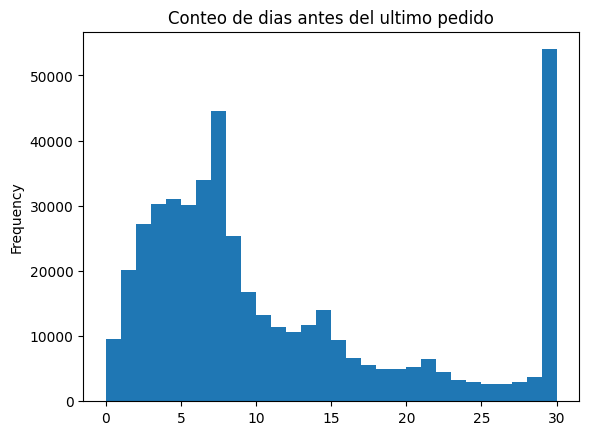

In [41]:
print(orders['days_since_prior_order'].min())
print(orders['days_since_prior_order'].max())

orders['days_since_prior_order'].plot(kind='hist', title='Conteo de dias antes del ultimo pedido', bins=30, xlabel='Cantidad de dias', ylabel='frecuencia')
plt.show

Escribe aquí tus conclusiones
si bien la mayoria espera 30 dias, tenemos una cantidad superios de las personas que espetan entre 5 y 10 dias.

<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a><br />
Los resultados son correctos
<br />
Hasta este punto no podemos saber si realmente los usuarios esperan 30 días para realizar otra compra o es el sistema el que agrupa todas las compras que sean mayores a 30 días en el día 30. Con la gráfica podemos observar que la mayoría de usuarios se concentra entre 1 y 9 días donde después los números descienden gradualmente
</div>


# [B] Intermedio (deben completarse todos para aprobar)

1. ¿Existe alguna diferencia entre las distribuciones `'order_hour_of_day'` de los miércoles y los sábados? Traza gráficos de barra de `'order_hour_of_day'` para ambos días en la misma figura y describe las diferencias que observes.
2. Grafica la distribución para el número de órdenes que hacen los clientes (es decir, cuántos clientes hicieron solo 1 pedido, cuántos hicieron 2, cuántos 3, y así sucesivamente...).
3. ¿Cuáles son los 20 principales productos que se piden con más frecuencia (muestra su identificación y nombre)?

### [B1] Diferencia entre miércoles y sábados para  `'order_hour_of_day'`. Traza gráficos de barra para los dos días y describe las diferencias que veas.

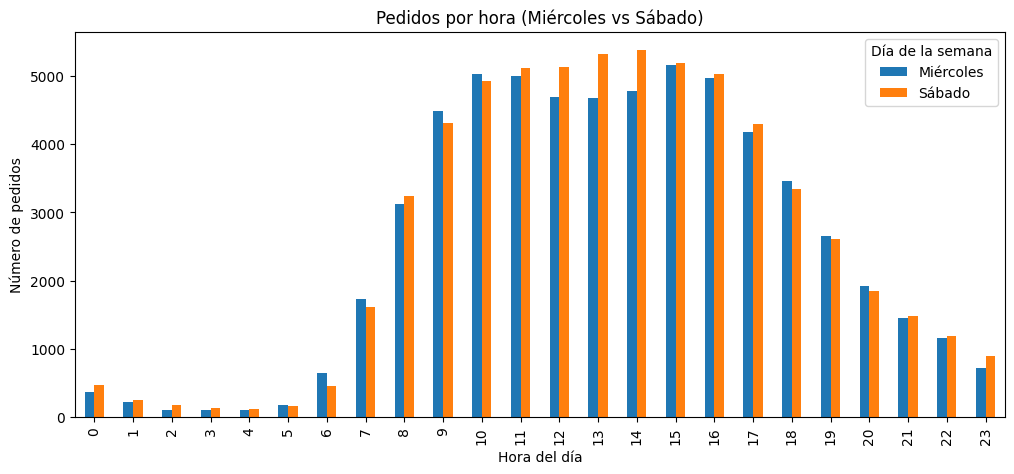

In [42]:
# Agrupar y contar por día y hora
grouped = orders[orders['order_dow'].isin([3, 6])].groupby(['order_hour_of_day', 'order_dow']).size().unstack()

# Graficar
grouped.plot(kind='bar', figsize=(12, 5))
plt.title('Pedidos por hora (Miércoles vs Sábado)')
plt.xlabel('Hora del día')
plt.ylabel('Número de pedidos')
plt.legend(title='Día de la semana', labels=['Miércoles', 'Sábado'])
plt.show()


<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a><br />
Bien hecho!
<br />
Buena manera de mostrar los resultados de ambos días en una misma grafica
</div>


Escribe aquí tus conclusiones

### [B2] ¿Cuál es la distribución para el número de pedidos por cliente?

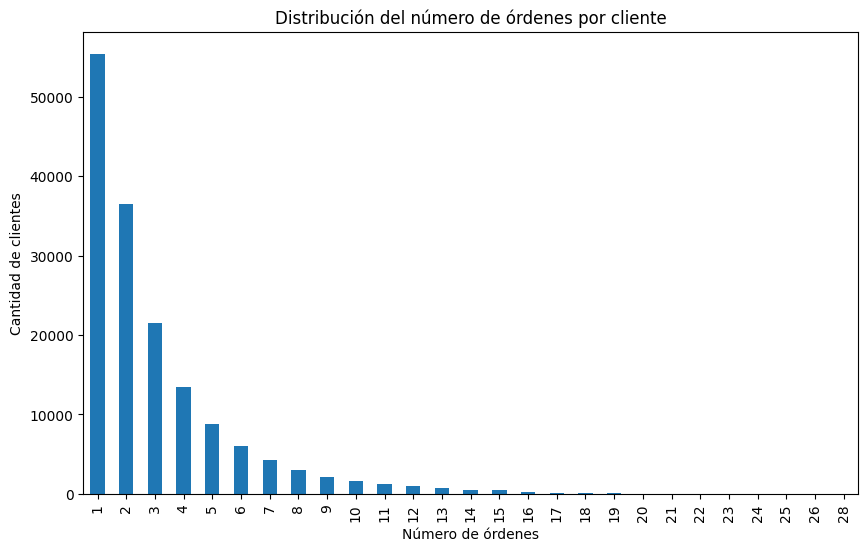

In [43]:

# Contar cuántos pedidos hizo cada usuario
orders_per_user = orders.groupby('user_id')['order_id'].count()

# Contar cuántos usuarios hicieron x numero de pedidos
distribution = orders_per_user.value_counts().sort_index()

# Graficar la distribución
distribution.plot(kind='bar', figsize=(10,6))
plt.title('Distribución del número de órdenes por cliente')
plt.xlabel('Número de órdenes')
plt.ylabel('Cantidad de clientes')
plt.show()


<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a><br />
Correcto!<br/> 

La mayoría de usuarios no ha hecho muchos pedidos, buenas observaciones.

</div>


Escribe aquí tus  la mayoria de usuarios solo ha realizado un pedido, lo cual nos puede indicar que tal vez son usuarios nuevos, por ejemplo.

### [B3] ¿Cuáles son los 20 productos más populares (muestra su ID y nombre)?

In [44]:
import pandas as pd

#produtos mas vendidos
top_products = order_products['product_id'].value_counts().head(20)

#crar un data frame
top_products_df = top_products.reset_index()
top_products_df.columns = ['product_id', 'order_count']

#unirdataframs
top_products_with_names = top_products_df.merge(
    products[['product_id', 'product_name']],
    on='product_id',
    how='left'
)

# Mostrar resultado
print(top_products_with_names)


    product_id  order_count              product_name
0        24852        66050                    BANANA
1        13176        53297    BAG OF ORGANIC BANANAS
2        21137        37039      ORGANIC STRAWBERRIES
3        21903        33971      ORGANIC BABY SPINACH
4        47209        29773      ORGANIC HASS AVOCADO
5        47766        24689           ORGANIC AVOCADO
6        47626        21495               LARGE LEMON
7        16797        20018              STRAWBERRIES
8        26209        19690                     LIMES
9        27845        19600        ORGANIC WHOLE MILK
10       27966        19197       ORGANIC RASPBERRIES
11       22935        15898      ORGANIC YELLOW ONION
12       24964        15292            ORGANIC GARLIC
13       45007        14584          ORGANIC ZUCCHINI
14       39275        13879       ORGANIC BLUEBERRIES
15       49683        13675            CUCUMBER KIRBY
16       28204        12544        ORGANIC FUJI APPLE
17        5876        12232 

<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a><br />
Los resultados son acertados!<br/>
Los clientes tienden a comprar productos naturales, buena manera de mostrar los resultados
</div>


Escribe aquí tus conclusiones

Los mas popluares son productos comestibles,

# [C] Difícil (deben completarse todos para aprobar)

1. ¿Cuántos artículos suelen comprar las personas en un pedido? ¿Cómo es la distribución?
2. ¿Cuáles son los 20 principales artículos que vuelven a pedirse con mayor frecuencia (muestra sus nombres e IDs de los productos)?
3. Para cada producto, ¿cuál es la tasa de repetición del pedido (número de repeticiones de pedido/total de pedidos?
4. Para cada cliente, ¿qué proporción de los productos que pidió ya los había pedido? Calcula la tasa de repetición de pedido para cada usuario en lugar de para cada producto.
5. ¿Cuáles son los 20 principales artículos que la gente pone primero en sus carritos (muestra las IDs de los productos, sus nombres, y el número de veces en que fueron el primer artículo en añadirse al carrito)?

### [C1] ¿Cuántos artículos compran normalmente las personas en un pedido? ¿Cómo es la distribución?

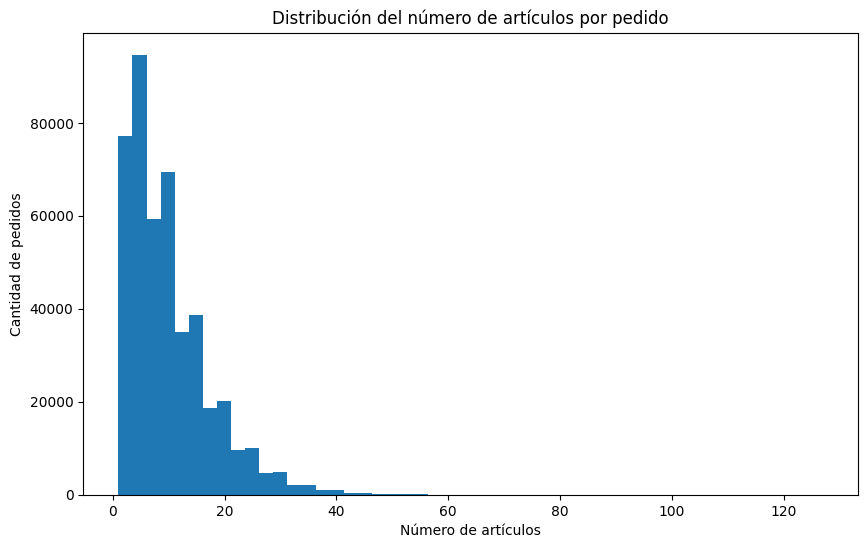

In [45]:
import matplotlib.pyplot as plt

#Contar cuántos productos tiene cada pedido
items_per_order = order_products.groupby('order_id')['product_id'].count()


#  Graficar la distribución
items_per_order.plot(kind='hist', bins=50, figsize=(10,6))
plt.title('Distribución del número de artículos por pedido')
plt.xlabel('Número de artículos')
plt.ylabel('Cantidad de pedidos')
plt.show()


<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a><br />
Bien hecho, el resultado es correcto, los usuarios suelen pedir alrededor de 10 articulos
</div>


Escribe aquí tus conclusiones

La mayoria de pedidos estan entre los 0 y 20 productos.

### [C2] ¿Cuáles son los 20 principales artículos que vuelven a pedirse con mayor frecuencia (muestra sus nombres e IDs de los productos)?

In [46]:
# Filtrar
reordered_products = order_products[order_products['reordered'] == 1]

# Conteo de ordenes del mismo producto
top_reordered = reordered_products['product_id'].value_counts().head(20)

# Crear nuevo DF
top_reordered_df = top_reordered.reset_index()
top_reordered_df.columns = ['product_id', 'reorder_count']

# unir info
top_reordered_with_names = top_reordered_df.merge(
    products[['product_id', 'product_name']],
    on='product_id',
    how='left'
)

# Mostrar resultado
print(top_reordered_with_names)


    product_id  reorder_count              product_name
0        24852          55763                    BANANA
1        13176          44450    BAG OF ORGANIC BANANAS
2        21137          28639      ORGANIC STRAWBERRIES
3        21903          26233      ORGANIC BABY SPINACH
4        47209          23629      ORGANIC HASS AVOCADO
5        47766          18743           ORGANIC AVOCADO
6        27845          16251        ORGANIC WHOLE MILK
7        47626          15044               LARGE LEMON
8        27966          14748       ORGANIC RASPBERRIES
9        16797          13945              STRAWBERRIES
10       26209          13327                     LIMES
11       22935          11145      ORGANIC YELLOW ONION
12       24964          10411            ORGANIC GARLIC
13       45007          10076          ORGANIC ZUCCHINI
14       49683           9538            CUCUMBER KIRBY
15       28204           8989        ORGANIC FUJI APPLE
16        8277           8836  APPLE HONEYCRISP 

<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a><br />
Correcto!<br/> 
Buena manera de mostrar los resultados, los productos naturales son consistentemente los más vendidos
</div>


Escribe aquí tus conclusiones 



### [C3] Para cada producto, ¿cuál es la proporción de las veces que se pide y que se vuelve a pedir?

In [47]:
# Agrupar y calcular
product_stats = order_products.groupby('product_id').agg(
    total_orders=('reordered', 'count'),
    total_reorders=('reordered', 'sum')
)

# calcular lo proporcion
product_stats['reorder_ratio'] = product_stats['total_reorders'] / product_stats['total_orders']

# combiar los productos
product_stats = product_stats.reset_index().merge(
    products[['product_id', 'product_name']],
    on='product_id',
    how='left'
)

# Mostrar top productos por proporción de reorden
print(product_stats.sort_values('reorder_ratio', ascending=False).head(10))


       product_id  total_orders  total_reorders  reorder_ratio  \
13453       14721             1               1            1.0   
19195       20949             3               3            1.0   
6136         6723            10              10            1.0   
6144         6732             3               3            1.0   
41319       45088             1               1            1.0   
41310       45078             1               1            1.0   
19258       21016             1               1            1.0   
19248       21005             2               2            1.0   
32273       35192             2               2            1.0   
32277       35197             1               1            1.0   

                                            product_name  
13453                            BONE STRENGTH TAKE CARE  
19195                           VANILLA SANDWICH COOKIES  
6136                                    PALMIERS- PETITE  
6144                   NATURALLY SPAR

Escribe aquí tus conclusiones

### [C4] Para cada cliente, ¿qué proporción de sus productos ya los había pedido?

In [48]:
# unir df
order_products_users = order_products.merge(
    orders[['order_id', 'user_id']],
    on='order_id',
    how='left'
)

# agrupar 
user_reorder_stats = order_products_users.groupby('user_id').agg(
    total_products=('product_id', 'count'),
    reordered_products=('reordered', 'sum')
)

# calcular proporcion
user_reorder_stats['reorder_ratio'] = user_reorder_stats['reordered_products'] / user_reorder_stats['total_products']

# Mostrar algunos resultados
print(user_reorder_stats.head(10))


         total_products  reordered_products  reorder_ratio
user_id                                                   
2                    26                   1       0.038462
4                     2                   0       0.000000
5                    12                   8       0.666667
6                     4                   0       0.000000
7                    14                  13       0.928571
11                   15                   3       0.200000
12                   12                   3       0.250000
13                   23                  13       0.565217
14                   61                  22       0.360656
15                   13                   7       0.538462


<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a><br />
Correcto!<br/>
Buena manera de realizar las proporciones
</div>


Escribe aquí tus conclusiones

### [C5] ¿Cuáles son los 20 principales artículos que las personas ponen primero en sus carritos?

In [50]:
# filtrado
first_in_cart = order_products[order_products['add_to_cart_order'] == 1]

# conteo de productos
top_first_products = first_in_cart['product_id'].value_counts().head(20).reset_index()
top_first_products.columns = ['product_id', 'first_add_count']

# unir df
top_first_products = top_first_products.merge(
    products[['product_id', 'product_name']],
    on='product_id',
    how='left'
)

# Mostrar resultado
print(top_first_products)


    product_id  first_add_count                 product_name
0        24852            15562                       BANANA
1        13176            11026       BAG OF ORGANIC BANANAS
2        27845             4363           ORGANIC WHOLE MILK
3        21137             3946         ORGANIC STRAWBERRIES
4        47209             3390         ORGANIC HASS AVOCADO
5        21903             3336         ORGANIC BABY SPINACH
6        47766             3044              ORGANIC AVOCADO
7        19660             2336                 SPRING WATER
8        16797             2308                 STRAWBERRIES
9        27966             2024          ORGANIC RASPBERRIES
10       44632             1914   SPARKLING WATER GRAPEFRUIT
11       49235             1797          ORGANIC HALF & HALF
12       47626             1737                  LARGE LEMON
13         196             1733                         SODA
14       38689             1397     ORGANIC REDUCED FAT MILK
15       26209          


<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a><br />
Correcto!<br/>
Una vez más los productos orgánicos estan en el top de la lista<br/>
</div>


Escribe aquí tus conclusiones

### Conclusion general del proyecto:

en conclusion creo que la preparacion de los datos es tan importante como los datos en si, tambien saber cual es la manera mas adecuada de tratar los datos faltantes o invalidos, ya que dependiendo el contexto puede ser mas conveniente una que otra por ejemplo promediarlos, o simplemente descartarlos dependiedno de porque no estan o si la cantidad es suficiente como para que afecte a la investigacion

## Comentario general del revisor
<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a><br />
Has realizado un buen trabajo, me doy cuenta de que has aplicado los conocimientos que has adquirido durante el curso, las conclusiones a las que llegaste son buenas y los procedimientos realizados son correctos. Considero que este es un proyecto que se empieza a asemejar más a algún proyecto que te pidan en un trabajo, a partir de análisis de este tipo se pueden diseñar estrategias de marketing específicas para ciertos productos o se pueden optimizar los procesos internos para tener disponibles más rápidamente los productos que se venden más seguido.<br/>
    

Continúa con el buen trabajo y mucho éxito en el siguiente Sprint!
</div>




<div class="alert alert-block alert-warning">
<b>Aspectos que pueden mejorar del proyecto</b> <a class="tocSkip"></a><br />

- Expandir un poco más (o agregar) observaciones intermedias, saber explicar con palabras nuestros hallazgos forma parte importante del análisis de los datos
- Tener mayor orden en el proyecto

</div>
